In [1]:
# Assignment 2: Simulated Driving Agent Behavior
# Genetic Algorithm based simulation

import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)

In [2]:
ROAD_WIDTH = 10
ROAD_LENGTH = 100

LEFT_BOUNDARY = -ROAD_WIDTH / 2
RIGHT_BOUNDARY = ROAD_WIDTH / 2

START_POSITION = np.array([0.0, 0.0])
GOAL_Y = ROAD_LENGTH

In [3]:
class DrivingAgent:
    def __init__(self, genes=None):
        self.position = START_POSITION.copy()
        self.velocity_y = 1.0
        self.alive = True
        self.distance_travelled = 0

        if genes is None:
            self.genes = np.random.uniform(-1, 1, 100)
        else:
            self.genes = genes.copy()

    def simulate(self):
        self.position = START_POSITION.copy()
        self.alive = True
        self.distance_travelled = 0

        for steering in self.genes:
            if not self.alive:
                break

            # Steering controls horizontal movement
            self.position[0] += steering

            # Move forward
            self.position[1] += self.velocity_y

            # Check road boundaries
            if (
                self.position[0] < LEFT_BOUNDARY
                or self.position[0] > RIGHT_BOUNDARY
            ):
                self.alive = False
                break

            self.distance_travelled += self.velocity_y

            # Stop if goal is reached
            if self.position[1] >= GOAL_Y:
                break

        return self.distance_travelled

In [4]:
POPULATION_SIZE = 50
GENERATIONS = 30

population = [
    DrivingAgent()
    for _ in range(POPULATION_SIZE)
]

print("Population size:", len(population))
print("Number of generations:", GENERATIONS)

Population size: 50
Number of generations: 30


In [5]:
def calculate_fitness(agent):
    agent.simulate()

    fitness = agent.distance_travelled

    # Reward reaching the goal
    if agent.position[1] >= GOAL_Y:
        fitness += 100

    return fitness

In [6]:
def evaluate_population(population):
    fitness_scores = []

    for agent in population:
        fitness = calculate_fitness(agent)
        fitness_scores.append(fitness)

    return np.array(fitness_scores)

In [7]:
def selection(population, fitness_scores):
    selected_indices = np.argsort(fitness_scores)[-10:]

    selected_agents = [
        population[i]
        for i in selected_indices
    ]

    return selected_agents

In [8]:
def crossover(parent1, parent2):
    crossover_point = random.randint(
        1,
        len(parent1.genes) - 1
    )

    child_genes = np.concatenate([
        parent1.genes[:crossover_point],
        parent2.genes[crossover_point:]
    ])

    return child_genes

In [9]:
def mutation(genes, mutation_rate=0.05):
    mutated_genes = genes.copy()

    for i in range(len(mutated_genes)):
        if random.random() < mutation_rate:
            mutated_genes[i] += np.random.normal(0, 0.3)

    return np.clip(mutated_genes, -1, 1)

In [10]:
def create_new_generation(selected_agents):
    new_population = []

    # Keep the best agent
    best_agent = max(
        selected_agents,
        key=lambda agent: agent.distance_travelled
    )

    new_population.append(
        DrivingAgent(best_agent.genes)
    )

    while len(new_population) < POPULATION_SIZE:

        parent1 = random.choice(selected_agents)
        parent2 = random.choice(selected_agents)

        child_genes = crossover(
            parent1,
            parent2
        )

        child_genes = mutation(child_genes)

        child = DrivingAgent(child_genes)

        new_population.append(child)

    return new_population

In [11]:
best_agents = []
best_fitness_history = []
average_fitness_history = []

for generation in range(GENERATIONS):

    fitness_scores = evaluate_population(population)

    best_index = np.argmax(fitness_scores)

    best_agent = population[best_index]

    best_agents.append(
        DrivingAgent(best_agent.genes)
    )

    best_fitness_history.append(
        fitness_scores[best_index]
    )

    average_fitness_history.append(
        np.mean(fitness_scores)
    )

    print(
        f"Generation {generation + 1:02d} | "
        f"Best Fitness: {fitness_scores[best_index]:.2f} | "
        f"Average Fitness: {np.mean(fitness_scores):.2f}"
    )

    selected_agents = selection(
        population,
        fitness_scores
    )

    population = create_new_generation(
        selected_agents
    )

Generation 01 | Best Fitness: 200.00 | Average Fitness: 90.08
Generation 02 | Best Fitness: 200.00 | Average Fitness: 147.38
Generation 03 | Best Fitness: 200.00 | Average Fitness: 178.08
Generation 04 | Best Fitness: 200.00 | Average Fitness: 176.42
Generation 05 | Best Fitness: 200.00 | Average Fitness: 188.96
Generation 06 | Best Fitness: 200.00 | Average Fitness: 169.90
Generation 07 | Best Fitness: 200.00 | Average Fitness: 185.86
Generation 08 | Best Fitness: 200.00 | Average Fitness: 186.86
Generation 09 | Best Fitness: 200.00 | Average Fitness: 191.60
Generation 10 | Best Fitness: 200.00 | Average Fitness: 181.74
Generation 11 | Best Fitness: 200.00 | Average Fitness: 187.28
Generation 12 | Best Fitness: 200.00 | Average Fitness: 192.26
Generation 13 | Best Fitness: 200.00 | Average Fitness: 189.66
Generation 14 | Best Fitness: 200.00 | Average Fitness: 184.44
Generation 15 | Best Fitness: 200.00 | Average Fitness: 197.42
Generation 16 | Best Fitness: 200.00 | Average Fitness: 

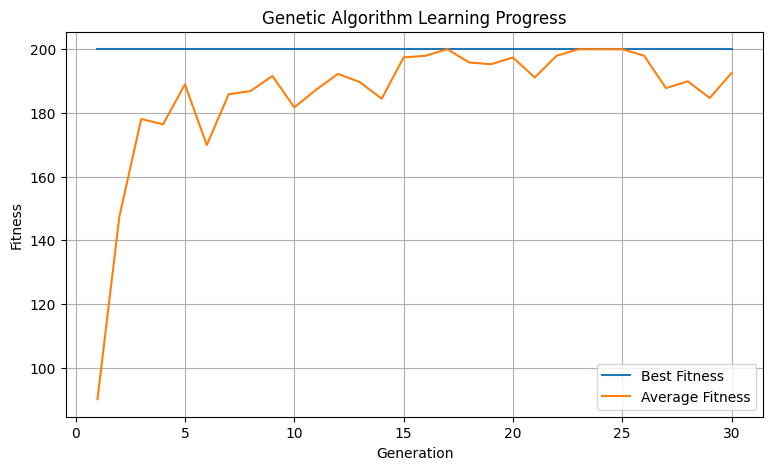

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    best_fitness_history,
    label="Best Fitness"
)

plt.plot(
    range(1, GENERATIONS + 1),
    average_fitness_history,
    label="Average Fitness"
)

plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.title("Genetic Algorithm Learning Progress")
plt.legend()
plt.grid(True)

plt.show()

In [13]:
best_generation_index = np.argmax(best_fitness_history)

best_agent = best_agents[best_generation_index]

best_fitness = best_fitness_history[best_generation_index]

print("Best Generation:", best_generation_index + 1)
print("Best Fitness:", round(best_fitness, 2))

Best Generation: 1
Best Fitness: 200.0


In [14]:
def get_agent_path(agent):
    position = START_POSITION.copy()

    path = [position.copy()]

    for steering in agent.genes:

        position[0] += steering
        position[1] += agent.velocity_y

        path.append(position.copy())

        if (
            position[0] < LEFT_BOUNDARY
            or position[0] > RIGHT_BOUNDARY
        ):
            break

        if position[1] >= GOAL_Y:
            break

    return np.array(path)


best_path = get_agent_path(best_agent)

print("Distance travelled:", round(best_path[-1, 1], 2))
print("Final position:", best_path[-1])

Distance travelled: 100.0
Final position: [  3.20916462 100.        ]


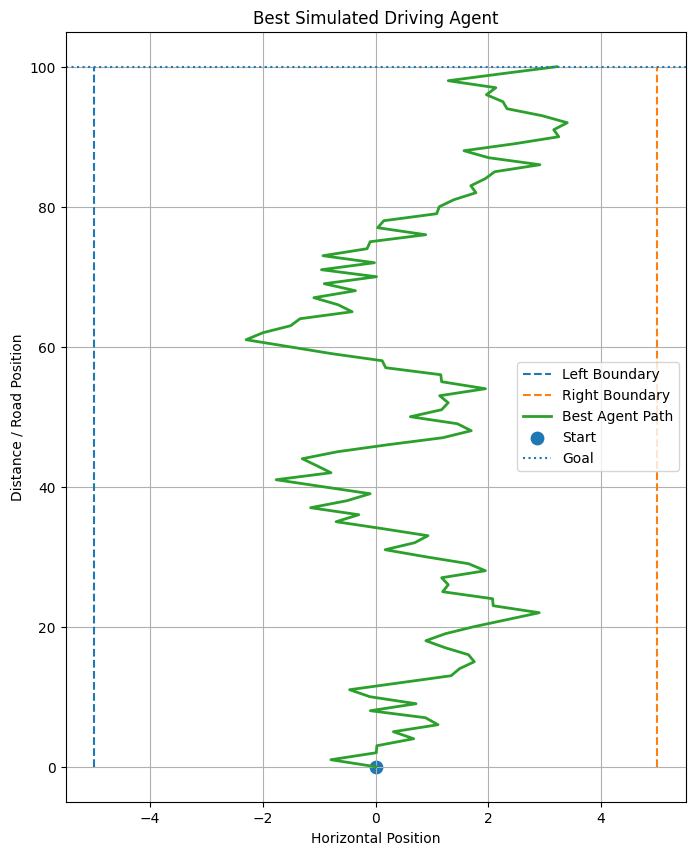

In [15]:
plt.figure(figsize=(8, 10))

# Road boundaries
plt.plot(
    [LEFT_BOUNDARY, LEFT_BOUNDARY],
    [0, ROAD_LENGTH],
    linestyle="--",
    label="Left Boundary"
)

plt.plot(
    [RIGHT_BOUNDARY, RIGHT_BOUNDARY],
    [0, ROAD_LENGTH],
    linestyle="--",
    label="Right Boundary"
)

# Agent path
plt.plot(
    best_path[:, 0],
    best_path[:, 1],
    linewidth=2,
    label="Best Agent Path"
)

# Starting point
plt.scatter(
    START_POSITION[0],
    START_POSITION[1],
    s=80,
    label="Start"
)

# Goal
plt.axhline(
    GOAL_Y,
    linestyle=":",
    label="Goal"
)

plt.xlabel("Horizontal Position")
plt.ylabel("Distance / Road Position")
plt.title("Best Simulated Driving Agent")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
reached_goal = best_path[-1, 1] >= GOAL_Y

print("   SIMULATED DRIVING AGENT - FINAL RESULT")
print("Genetic Algorithm generations:", GENERATIONS)
print("Population size:", POPULATION_SIZE)
print("Best fitness:", round(best_fitness, 2))
print("Distance travelled:", round(best_path[-1, 1], 2))
print("Goal reached:", reached_goal)
print("==========================================")